# Dimensionality Reduction Using Different Methods In Unsupervised ML

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import fetch_openml
from sklearn.decomposition import (PCA, IncrementalPCA, MiniBatchDictionaryLearning, MiniBatchSparsePCA, KernelPCA, TruncatedSVD, FastICA)
from sklearn.random_projection import (GaussianRandomProjection, SparseRandomProjection, johnson_lindenstrauss_min_dim)
from sklearn.manifold import Isomap, MDS, LocallyLinearEmbedding, TSNE

c:\Users\uditm\anaconda3\envs\intelxpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## fetch_openml downloads MNIST

In [2]:
X, y = fetch_openml("mnist_784", return_X_y=True, as_frame=False)
X.shape

(70000, 784)

In [4]:
X = X/255
y = y.astype(int)
X.max(), y[:10]

(0.00392156862745098, array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4]))

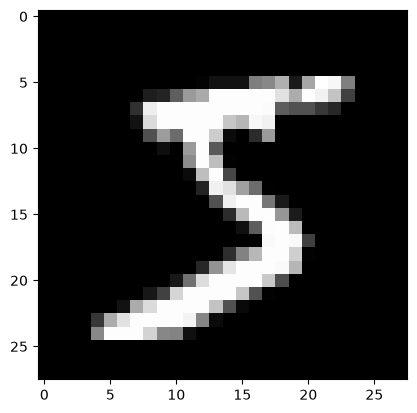

In [8]:
plt.imshow(X[0].reshape(28, 28), cmap='gray')

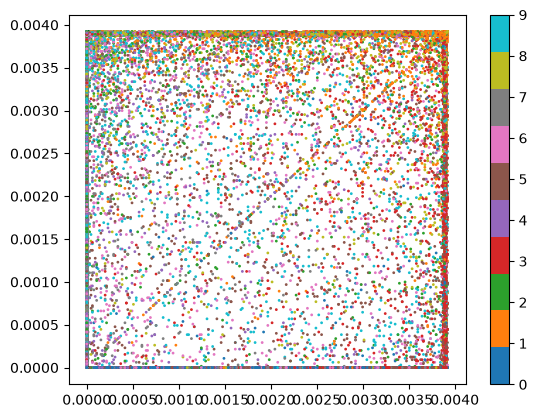

In [9]:
plt.scatter(X[:, 350], X[:, 406], c=y, s=1, cmap="tab10")
plt.colorbar()

# PCA

In [10]:
pca = PCA()
X_pca = pca.fit_transform(X)
pca.explained_variance_ratio_[:10]

array([0.09746116, 0.07155445, 0.06149531, 0.05403385, 0.04888934,
       0.04305227, 0.03278262, 0.02889642, 0.02758364, 0.0234214 ])

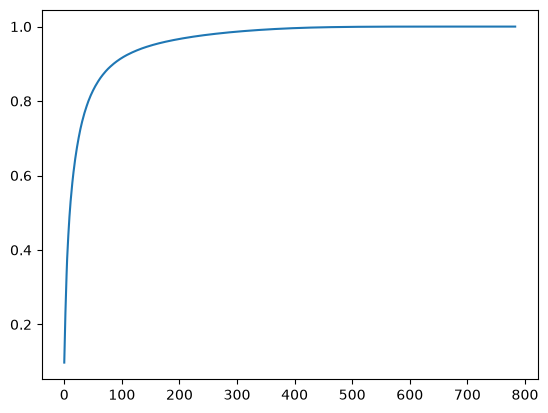

In [11]:
plt.plot(pca.explained_variance_ratio_.cumsum())

In [12]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X)
pca.n_components_

154

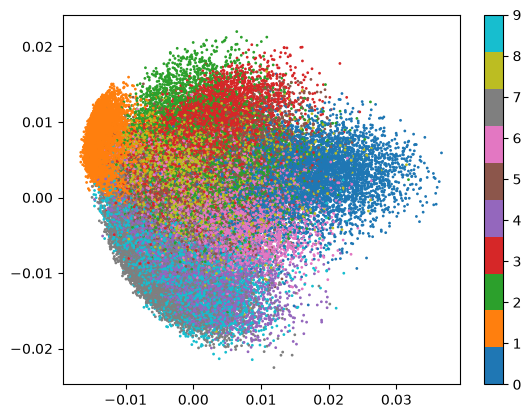

In [13]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=1, cmap="tab10")
plt.colorbar()

# Components as Images

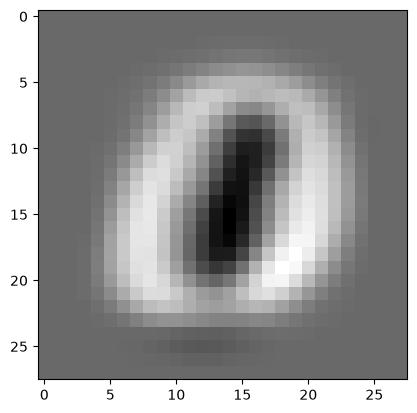

In [14]:
plt.imshow(pca.components_[0].reshape(28, 28), cmap="gray")

# Rebuild Digits

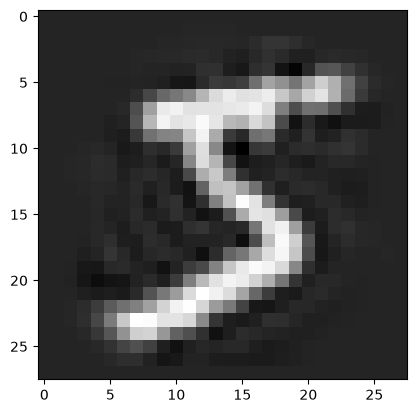

In [15]:
X_back = pca.inverse_transform(X_pca)
plt.imshow(X_back[0].reshape(28, 28), cmap="gray")

In [16]:
errors = ((X-X_back)**2).sum(axis=1)
errors.argmax()

13650

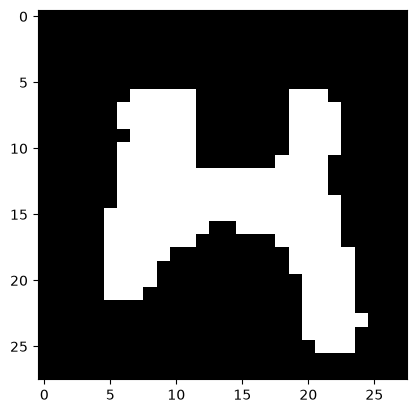

In [17]:
plt.imshow(X[errors.argmax()].reshape(28, 28), cmap="gray")

# Incremental PCA

In [18]:
ipca = IncrementalPCA(n_components=154)
for chunk in np.array_split(X, 20):
    ipca.partial_fit(chunk)

ipca.explained_variance_ratio_.sum(), pca.explained_variance_ratio_.sum()

(0.9499917245596572, 0.9503499702078614)

# Sparse PCA

In [19]:
spca = MiniBatchSparsePCA(n_components=50)
spca.fit(X[:10000])
X_spca = spca.transform(X)
X_spca.shape


(70000, 50)

In [20]:
(spca.components_==0).mean(), (pca.components_==0).mean()

(1.0, 0.048220911741319906)

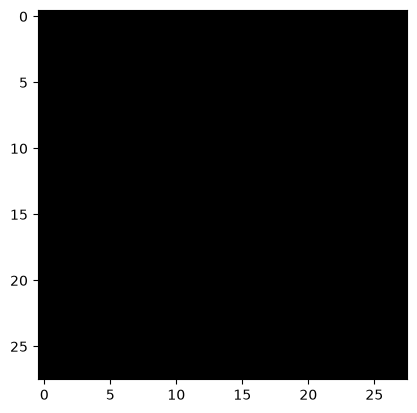

In [21]:
plt.imshow(spca.components_[0].reshape(28, 28), cmap="gray")

# Kernel PCA

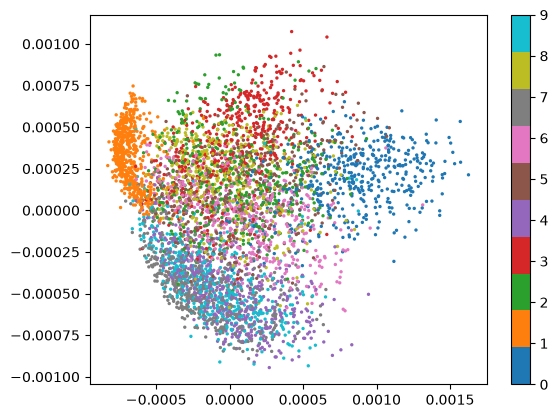

In [23]:
kpca = KernelPCA(n_components=2, kernel='rbf')
X_kpca = kpca.fit_transform(X[:5000])
plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=y[:5000], s=2, cmap="tab10")
plt.colorbar()

# Truncated SVD

In [24]:
svd = TruncatedSVD(n_components=154)
X_svd = svd.fit_transform(X)
svd.explained_variance_ratio_.sum()

0.9501926952647458